# 📊 Clustering Karyawan — K-Means Analysis

- **Dataset** : `Report.csv`
- **Metode** : K-Means Clustering dengan MinMax Scaling
- **Evaluasi** : Elbow Method, Silhouette, Davies-Bouldin, Calinski-Harabasz


## 1. Import Library

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score
)
import joblib, os, json
from collections import Counter

print('done')

done


## 2. Load & Preprocessing Data

In [21]:
## 2. Load & Preprocessing Data

import pandas as pd

# ── Load ──────────────────────────────────────────────────────
df = pd.read_excel('Report.xlsx')

# ── Pilih kolom ───────────────────────────────────────────────
kolom_yang_dipilih = [
    'Username',
    'Tanggal Visit',
    'Area',
    'Nama Karyawan',
    'Region',
    'Facing',
    'Is FIFO/FEFO',
    'Is Price Tag Available'
]
df = df[kolom_yang_dipilih].copy()

# ── Tipe data dasar ───────────────────────────────────────────
df['Tanggal Visit'] = pd.to_datetime(df['Tanggal Visit'], errors='coerce')
df['Facing']        = pd.to_numeric(df['Facing'], errors='coerce').fillna(0).clip(lower=0)
df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].astype(str).str.upper().str.strip()
df['Is Price Tag Available'] = df['Is Price Tag Available'].astype(str).str.upper().str.strip()

# ── FIX 1 — Filter Username tidak valid (bukan karyawan) ─────
# Semua karyawan valid memiliki format Username: ID-XXXXXXX
# Username seperti PERMATA GROUP, SAT, SAT-LARGE = data produk/brand
n_sebelum  = len(df)
df         = df[df['Username'].astype(str).str.match(r'^ID-', na=False)].copy()
n_sesudah  = len(df)
print(f"Baris dibuang (Username bukan ID-xxx) : {n_sebelum - n_sesudah}")
print(f"Baris tersisa (karyawan valid)        : {n_sesudah}")

# ── FIX 2 — Buang baris dengan FIFO/FEFO = '-1' ──────────────
# Nilai -1 = sentinel data kotor dari sistem sumber
mask_invalid = df['Is FIFO/FEFO'] == '-1'
n_invalid    = mask_invalid.sum()
df           = df[~mask_invalid].copy()
print(f"Baris dengan FIFO/FEFO=-1 dibuang     : {n_invalid}")

# ── FIX 3 — Isi NaN pada KPI dengan 'TIDAK' ──────────────────
# Karyawan yang tidak mengisi KPI = dianggap tidak comply
valid_kpi = {'YA', 'TIDAK'}
df['Is FIFO/FEFO'] = df['Is FIFO/FEFO'].apply(
    lambda x: x if x in valid_kpi else 'TIDAK'
)
df['Is Price Tag Available'] = df['Is Price Tag Available'].apply(
    lambda x: x if x in valid_kpi else 'TIDAK'
)

# ── Verifikasi ────────────────────────────────────────────────
print()
print('Distribusi Is FIFO/FEFO  :', df['Is FIFO/FEFO'].value_counts().to_dict())
print('Distribusi Price Tag     :', df['Is Price Tag Available'].value_counts().to_dict())
print('Facing min / max         :', df['Facing'].min(), '/', df['Facing'].max())

# ── Buat Report_Clean (satu baris per karyawan unik) ─────────
visit_count = df.groupby('Username')['Tanggal Visit'].count().reset_index()
visit_count.columns = ['Username', 'Visit Count']

df_clean = df.merge(visit_count, on='Username', how='left')
df_clean = df_clean.drop_duplicates(
    subset=['Username', 'Nama Karyawan', 'Region']
).reset_index(drop=True)

df_clean.to_excel('Report_Clean.xlsx', index=False)
print(f"\nReport_Clean.xlsx disimpan: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom")

# ── Groupby untuk clustering ──────────────────────────────────
df_grouped = (
    df.groupby('Username')
    .agg(
        Facing      = ('Facing',                 'mean'),
        Is_FIFO     = ('Is FIFO/FEFO',           lambda x: (x == 'YA').mean()),
        Is_PriceTag = ('Is Price Tag Available', lambda x: (x == 'YA').mean()),
        visit_count = ('Tanggal Visit',          'count'),
    )
    .rename(columns={
        'Is_FIFO'    : 'Is FIFO/FEFO',
        'Is_PriceTag': 'Is Price Tag Available',
    })
    .reset_index()
    .fillna(0)
)

employee_info = df[['Username', 'Nama Karyawan', 'Area', 'Region']].drop_duplicates('Username')

print(f'Total karyawan valid untuk clustering: {len(df_grouped)}')
df_grouped.describe().round(3)

Baris dibuang (Username bukan ID-xxx) : 202
Baris tersisa (karyawan valid)        : 523062
Baris dengan FIFO/FEFO=-1 dibuang     : 0

Distribusi Is FIFO/FEFO  : {'TIDAK': 263252, 'YA': 259810}
Distribusi Price Tag     : {'TIDAK': 264088, 'YA': 258974}
Facing min / max         : 0.0 / 730.0

Report_Clean.xlsx disimpan: 93 baris, 9 kolom
Total karyawan valid untuk clustering: 79


,Facing,Is FIFO/FEFO,Is Price Tag Available,visit_count
count,79.000,79.000,79.000,79.000
mean,1.736,0.525,0.524,6621.038
std,0.675,0.156,0.158,2616.228
min,0.368,0.306,0.306,1138.000
25%,1.294,0.439,0.439,5121.000
50%,1.579,0.474,0.474,6499.000
75%,2.095,0.553,0.553,7636.000
max,4.283,0.942,0.942,15616.000


In [22]:
df['Tanggal Visit']          = pd.to_datetime(df['Tanggal Visit'], errors='coerce')
df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].astype(str).str.upper().str.strip()
df['Is Price Tag Available'] = df['Is Price Tag Available'].astype(str).str.upper().str.strip()

print('Distribusi Is FIFO/FEFO  :', df['Is FIFO/FEFO'].value_counts().to_dict())
print('Distribusi Price Tag     :', df['Is Price Tag Available'].value_counts().to_dict())

df_grouped = df.groupby('Username').agg({
    'Facing'                : 'mean',
    'Is FIFO/FEFO'          : lambda x: (x == 'YA').mean(),
    'Is Price Tag Available': lambda x: (x == 'YA').mean(),
    'Tanggal Visit'         : 'count'
}).rename(columns={'Tanggal Visit': 'visit_count'}).reset_index().fillna(0)

employee_info = df[['Username', 'Nama Karyawan', 'Area', 'Region']].drop_duplicates('Username')

print(f'Total karyawan unik: {len(df_grouped)}')
df_grouped.describe().round(3)

Distribusi Is FIFO/FEFO  : {'TIDAK': 263252, 'YA': 259810}
Distribusi Price Tag     : {'TIDAK': 264088, 'YA': 258974}
Total karyawan unik: 79


,Facing,Is FIFO/FEFO,Is Price Tag Available,visit_count
count,79.000,79.000,79.000,79.000
mean,1.736,0.525,0.524,6621.038
std,0.675,0.156,0.158,2616.228
min,0.368,0.306,0.306,1138.000
25%,1.294,0.439,0.439,5121.000
50%,1.579,0.474,0.474,6499.000
75%,2.095,0.553,0.553,7636.000
max,4.283,0.942,0.942,15616.000


## 3. Distribusi Data — Sebelum & Sesudah Scaling

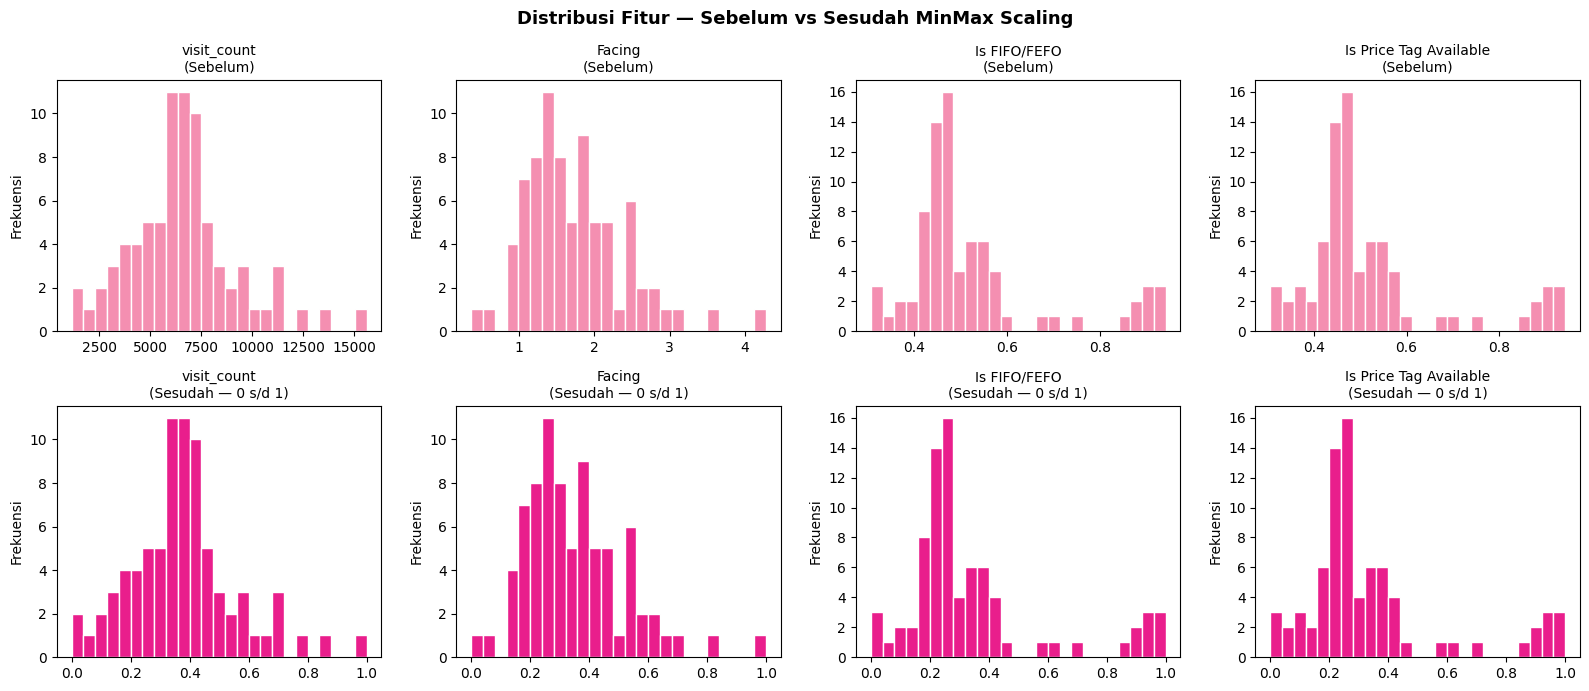


Statistik setelah scaling:
  Min : [0. 0. 0. 0.]
  Max : [1. 1. 1. 1.]
  Mean: [0.379 0.35  0.345 0.342]


In [23]:
feature_cols = ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']
X = df_grouped[feature_cols].values

scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle('Distribusi Fitur — Sebelum vs Sesudah MinMax Scaling', fontsize=13, fontweight='bold')

for i, col in enumerate(feature_cols):
    axes[0, i].hist(X[:, i],        bins=25, color='#F48FB1', edgecolor='white')
    axes[0, i].set_title(f'{col}\n(Sebelum)', fontsize=10)
    axes[0, i].set_ylabel('Frekuensi')

    axes[1, i].hist(X_scaled[:, i], bins=25, color='#E91E8C', edgecolor='white')
    axes[1, i].set_title(f'{col}\n(Sesudah — 0 s/d 1)', fontsize=10)
    axes[1, i].set_ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('plot_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nStatistik setelah scaling:')
print(f'  Min : {X_scaled.min(axis=0).round(3)}')
print(f'  Max : {X_scaled.max(axis=0).round(3)}')
print(f'  Mean: {X_scaled.mean(axis=0).round(3)}')

## 4. Menentukan K Optimal — 4 Metrik Evaluasi

In [24]:
K_RANGE = range(2, 11)

inertia_list = []
sil_list     = []
dbi_list     = []
ch_list      = []

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, labels))
    dbi_list.append(davies_bouldin_score(X_scaled, labels))
    ch_list.append(calinski_harabasz_score(X_scaled, labels))

# Pilih K optimal via majority voting
best_sil_k = list(K_RANGE)[sil_list.index(max(sil_list))]
best_dbi_k = list(K_RANGE)[dbi_list.index(min(dbi_list))]
best_ch_k  = list(K_RANGE)[ch_list.index(max(ch_list))]

votes      = [best_sil_k, best_dbi_k, best_ch_k]
vote_count = Counter(votes)
BEST_K     = vote_count.most_common(1)[0][0]

# Jika semua berbeda → pakai Silhouette sebagai tie-breaker
if vote_count.most_common(1)[0][1] == 1:
    BEST_K   = best_sil_k
    tie_note = '(tie-break → Silhouette)'
else:
    tie_note = ''

print(f'\n=== Pemilihan K Optimal ===')
print(f'  Silhouette terbaik       : k={best_sil_k} ({max(sil_list):.4f})')
print(f'  Davies-Bouldin terbaik   : k={best_dbi_k} ({min(dbi_list):.4f})')
print(f'  Calinski-Harabasz terbaik: k={best_ch_k} ({max(ch_list):.2f})')
print(f'  Hasil voting             : {votes}')
print(f'   K yang optimal adalah    : k={BEST_K} {tie_note}')


=== Pemilihan K Optimal ===
  Silhouette terbaik       : k=2 (0.6182)
  Davies-Bouldin terbaik   : k=2 (0.5584)
  Calinski-Harabasz terbaik: k=2 (109.85)
  Hasil voting             : [2, 2, 2]
   K yang optimal adalah    : k=2 


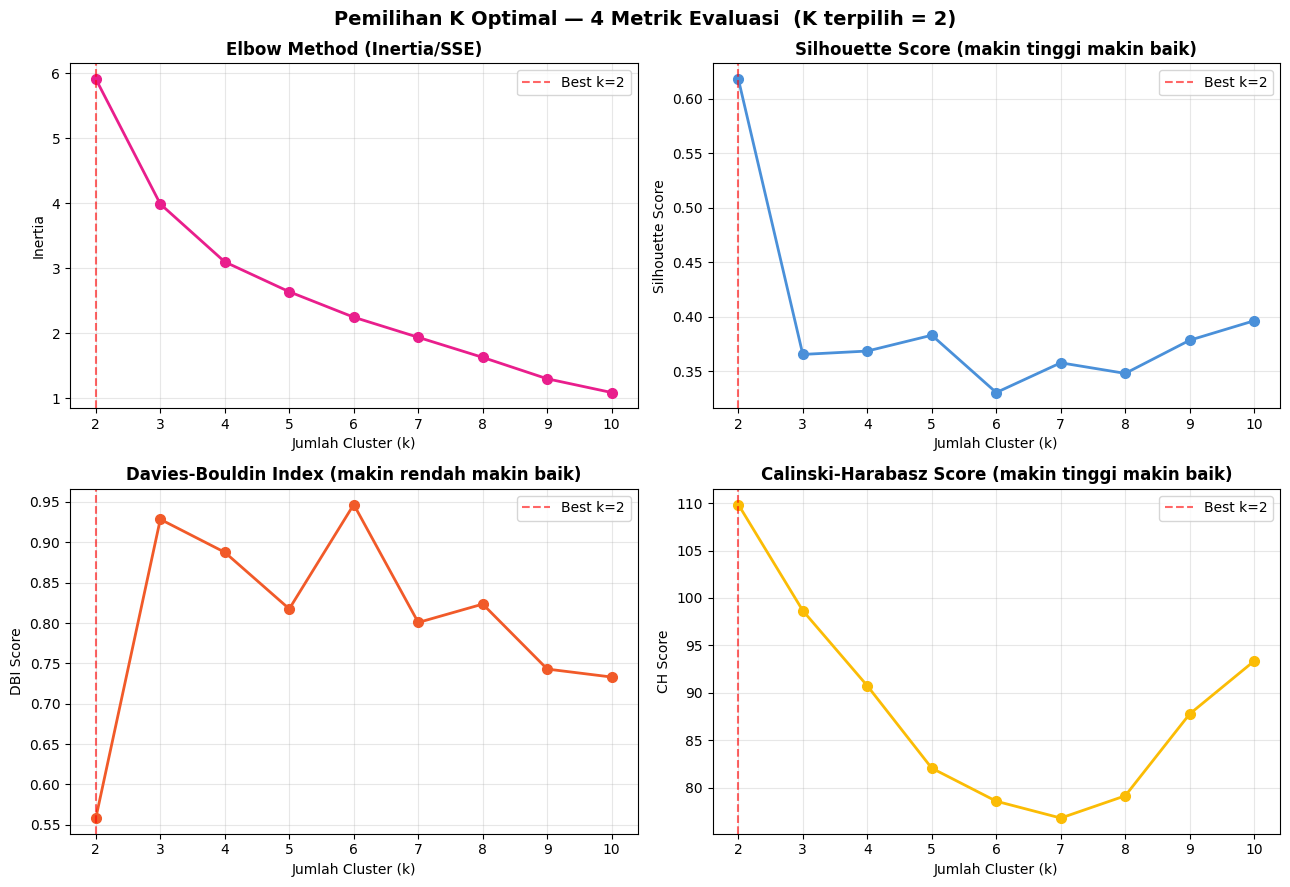


=== Tabel Evaluasi per K ===
 k  Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz Terpilih
 2     5.91      0.6182          0.5584             109.85        ✅
 3     3.99      0.3652          0.9285              98.67         
 4     3.10      0.3683          0.8876              90.75         
 5     2.64      0.3829          0.8175              82.07         
 6     2.25      0.3302          0.9468              78.59         
 7     1.94      0.3576          0.8007              76.82         
 8     1.63      0.3478          0.8234              79.16         
 9     1.30      0.3783          0.7430              87.79         
10     1.09      0.3962          0.7331              93.36         


In [25]:
# Plot 4 metrik
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle(f'Pemilihan K Optimal — 4 Metrik Evaluasi  (K terpilih = {BEST_K})',
             fontsize=14, fontweight='bold')

axes[0,0].plot(K_RANGE, inertia_list, 'o-', color='#E91E8C', linewidth=2, markersize=7)
axes[0,0].axvline(x=BEST_K, color='red', linestyle='--', alpha=0.6, label=f'Best k={BEST_K}')
axes[0,0].set_title('Elbow Method (Inertia/SSE)', fontweight='bold')
axes[0,0].set_xlabel('Jumlah Cluster (k)'); axes[0,0].set_ylabel('Inertia')
axes[0,0].grid(alpha=0.3); axes[0,0].set_xticks(list(K_RANGE)); axes[0,0].legend()

axes[0,1].plot(K_RANGE, sil_list, 'o-', color='#4A90D9', linewidth=2, markersize=7)
axes[0,1].axvline(x=best_sil_k, color='red', linestyle='--', alpha=0.6, label=f'Best k={best_sil_k}')
axes[0,1].set_title('Silhouette Score (makin tinggi makin baik)', fontweight='bold')
axes[0,1].set_xlabel('Jumlah Cluster (k)'); axes[0,1].set_ylabel('Silhouette Score')
axes[0,1].legend(); axes[0,1].grid(alpha=0.3); axes[0,1].set_xticks(list(K_RANGE))

axes[1,0].plot(K_RANGE, dbi_list, 'o-', color='#F15A29', linewidth=2, markersize=7)
axes[1,0].axvline(x=best_dbi_k, color='red', linestyle='--', alpha=0.6, label=f'Best k={best_dbi_k}')
axes[1,0].set_title('Davies-Bouldin Index (makin rendah makin baik)', fontweight='bold')
axes[1,0].set_xlabel('Jumlah Cluster (k)'); axes[1,0].set_ylabel('DBI Score')
axes[1,0].legend(); axes[1,0].grid(alpha=0.3); axes[1,0].set_xticks(list(K_RANGE))

axes[1,1].plot(K_RANGE, ch_list, 'o-', color='#FBBC05', linewidth=2, markersize=7)
axes[1,1].axvline(x=best_ch_k, color='red', linestyle='--', alpha=0.6, label=f'Best k={best_ch_k}')
axes[1,1].set_title('Calinski-Harabasz Score (makin tinggi makin baik)', fontweight='bold')
axes[1,1].set_xlabel('Jumlah Cluster (k)'); axes[1,1].set_ylabel('CH Score')
axes[1,1].legend(); axes[1,1].grid(alpha=0.3); axes[1,1].set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig('plot_pemilihan_k.png', dpi=150, bbox_inches='tight')
plt.show()

eval_df = pd.DataFrame({
    'k'                : list(K_RANGE),
    'Inertia'          : [round(v, 2) for v in inertia_list],
    'Silhouette'       : [round(v, 4) for v in sil_list],
    'Davies-Bouldin'   : [round(v, 4) for v in dbi_list],
    'Calinski-Harabasz': [round(v, 2) for v in ch_list],
    'Terpilih'         : ['✅' if k == BEST_K else '' for k in K_RANGE],
})
print('\n=== Tabel Evaluasi per K ===')
print(eval_df.to_string(index=False))

## 5. Training Model Final — K Optimal

In [26]:
print(f'\n> Training KMeans dengan k={BEST_K} (hasil voting metrik evaluasi)')

kmeans_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(X_scaled)
df_grouped['cluster'] = labels_final

#label otomatis berdasarkan rata-rata visit_count
cluster_visit_mean = df_grouped.groupby('cluster')['visit_count'].mean().sort_values(ascending=False)

rank_labels = {}
n = len(cluster_visit_mean)
for rank, (cid, _) in enumerate(cluster_visit_mean.items()):
    if n == 2:
        rank_labels[cid] = 'High' if rank == 0 else 'Low'
    elif n == 3:
        rank_labels[cid] = ['High', 'Medium', 'Low'][rank]
    else:
        rank_labels[cid] = f'Tier {rank + 1}'

df_grouped['cluster_label'] = df_grouped['cluster'].map(rank_labels)

print(f'\nMapping cluster → label (berdasarkan visit_count rata-rata):')
for cid, lbl in rank_labels.items():
    n_kary = (labels_final == cid).sum()
    vm     = cluster_visit_mean[cid]
    print(f'  Cluster {cid} → {lbl:<8}  ({n_kary} karyawan, visit_mean={vm:.1f})')

print(f'\nCentroid (scaled):')
print(pd.DataFrame(kmeans_final.cluster_centers_, columns=feature_cols).round(4))


> Training KMeans dengan k=2 (hasil voting metrik evaluasi)

Mapping cluster → label (berdasarkan visit_count rata-rata):
  Cluster 0 → High      (67 karyawan, visit_mean=7062.1)
  Cluster 1 → Low       (12 karyawan, visit_mean=4158.5)

Centroid (scaled):
   visit_count  Facing  Is FIFO/FEFO  Is Price Tag Available
0       0.4092  0.3195        0.2520                  0.2491
1       0.2086  0.5176        0.8626                  0.8625


## 6. Evaluasi Model

       EVALUASI MODEL K-MEANS  (k=2)          
  Silhouette Score      : 0.6182  → Cukup baik
  Davies-Bouldin Index  : 0.5584  → Baik
  Calinski-Harabasz     : 109.85
  Inertia (SSE)         : 5.91
  Catatan:
  - Silhouette > 0.5  = cluster cukup terpisah
  - DBI < 1.0         = cluster tidak tumpang tindih
  - CH makin tinggi   = cluster makin padat & terpisah


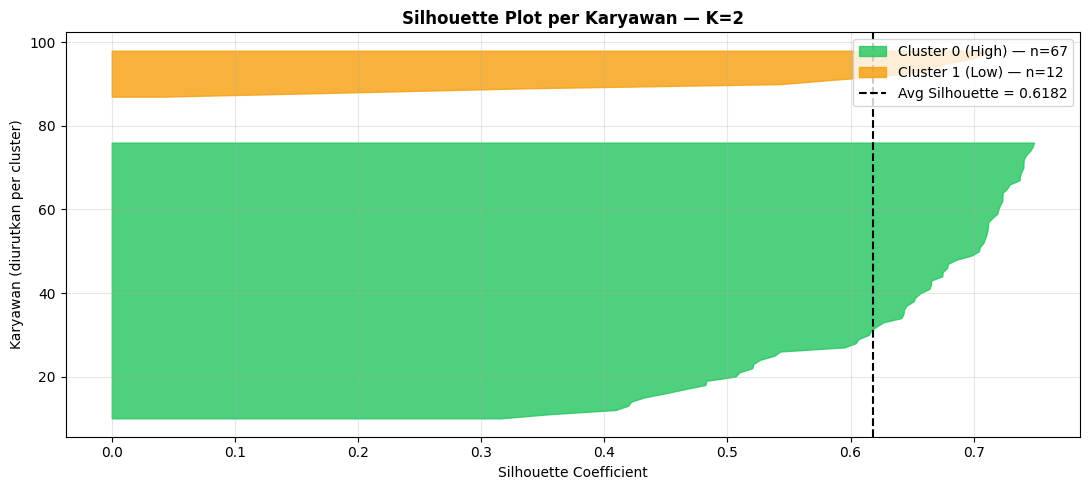


Karyawan dengan Silhouette < 0 (ambigu): 0


In [27]:
sil  = silhouette_score(X_scaled, labels_final)
dbi  = davies_bouldin_score(X_scaled, labels_final)
ch   = calinski_harabasz_score(X_scaled, labels_final)
sse  = kmeans_final.inertia_

if sil >= 0.70:   sil_interp = 'Sangat kuat'
elif sil >= 0.50: sil_interp = 'Cukup baik'
elif sil >= 0.25: sil_interp = 'Lemah'
else:             sil_interp = 'Tidak berarti'

if dbi < 0.5:   dbi_interp = 'Sangat baik'
elif dbi < 1.0: dbi_interp = 'Baik'
elif dbi < 1.5: dbi_interp = 'Cukup'
else:           dbi_interp = 'Buruk'

print('=' * 55)
print(f'       EVALUASI MODEL K-MEANS  (k={BEST_K})          ')
print('=' * 55)
print(f'  Silhouette Score      : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index  : {dbi:.4f}  → {dbi_interp}')
print(f'  Calinski-Harabasz     : {ch:.2f}')
print(f'  Inertia (SSE)         : {sse:.2f}')
print('=' * 55)
print('  Catatan:')
print('  - Silhouette > 0.5  = cluster cukup terpisah')
print('  - DBI < 1.0         = cluster tidak tumpang tindih')
print('  - CH makin tinggi   = cluster makin padat & terpisah')
print('=' * 55)

sil_samples = silhouette_samples(X_scaled, labels_final)
df_grouped['silhouette_sample'] = sil_samples

# Silhouette plot (dinamis untuk semua K)
ordered_labels = list(rank_labels.items())   # [(cid, label), ...] urut visit desc

palette = ['#22c55e', '#f59e0b', '#ef4444', '#6366f1',
           '#ec4899', '#14b8a6', '#f97316', '#8b5cf6', '#06b6d4']

fig, ax = plt.subplots(figsize=(11, 5))
y_lower = 10
for idx, (cid, lbl) in enumerate(ordered_labels):
    vals    = np.sort(sil_samples[labels_final == cid])
    size    = vals.shape[0]
    y_upper = y_lower + size
    color   = palette[idx % len(palette)]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                     facecolor=color, edgecolor=color, alpha=0.8,
                     label=f'Cluster {cid} ({lbl}) — n={size}')
    y_lower = y_upper + 10

ax.axvline(x=sil, color='black', linestyle='--', linewidth=1.5,
           label=f'Avg Silhouette = {sil:.4f}')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Karyawan (diurutkan per cluster)')
ax.set_title(f'Silhouette Plot per Karyawan — K={BEST_K}', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plot_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

ambiguous = df_grouped[df_grouped['silhouette_sample'] < 0][
    ['Username', 'cluster_label', 'silhouette_sample']]
print(f'\nKaryawan dengan Silhouette < 0 (ambigu): {len(ambiguous)}')
if len(ambiguous) > 0:
    print(ambiguous.sort_values('silhouette_sample').head(10).to_string(index=False))

## 7. Analisis Karakteristik Cluster

=== Rata-rata Fitur per Cluster ===
         visit_count  Facing  Is FIFO/FEFO  Is Price Tag Available
Cluster                                                           
High         7062.09   1.619         0.466                   0.464
Low          4158.50   2.395         0.855                   0.855

Jumlah karyawan per cluster:
cluster_label
High    67
Low     12
Name: count, dtype: int64


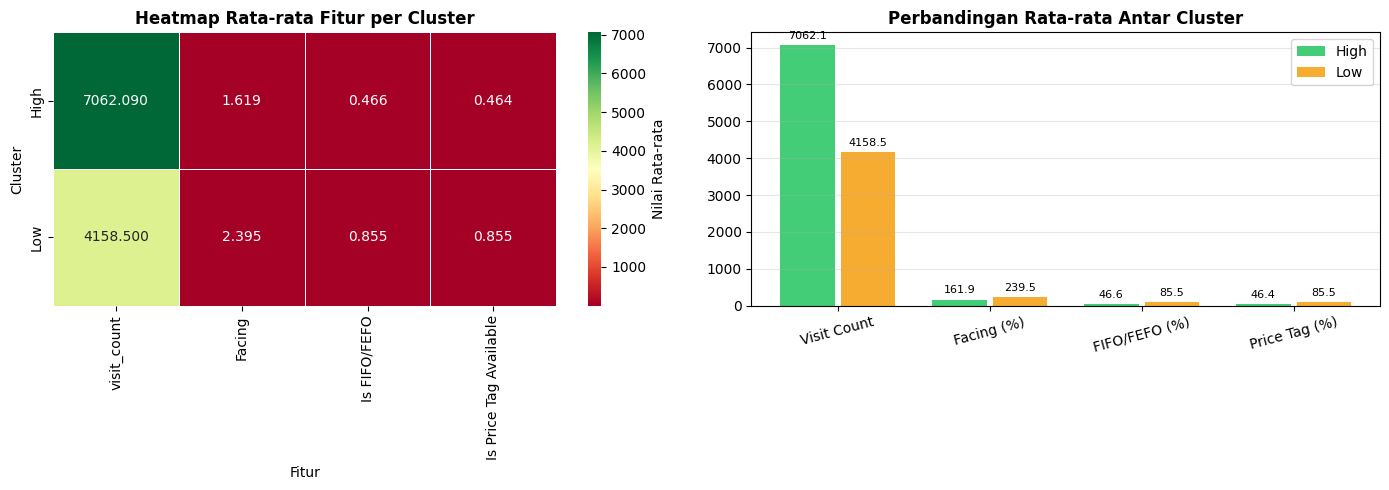

In [28]:
label_order     = [lbl for _, lbl in ordered_labels]
cluster_summary = (df_grouped.groupby('cluster_label')[feature_cols]
                              .mean()
                              .round(3)
                              .reindex(label_order))
cluster_summary.index.name = 'Cluster'

print('=== Rata-rata Fitur per Cluster ===')
print(cluster_summary)
print(f'\nJumlah karyawan per cluster:')
print(df_grouped['cluster_label'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cluster_summary, annot=True, fmt='.3f', cmap='RdYlGn',
            linewidths=0.5, ax=axes[0], cbar_kws={'label': 'Nilai Rata-rata'})
axes[0].set_title('Heatmap Rata-rata Fitur per Cluster', fontweight='bold')
axes[0].set_xlabel('Fitur')

x     = np.arange(len(feature_cols))
width = 0.8 / BEST_K
for idx, lbl in enumerate(label_order):
    offset = (idx - (BEST_K - 1) / 2) * width
    vals   = cluster_summary.loc[lbl].values.copy()
    vals[1:] *= 100   # Facing, FIFO, PriceTag → persen
    bars = axes[1].bar(x + offset, vals, width * 0.9,
                       label=lbl, color=palette[idx % len(palette)], alpha=0.85)
    axes[1].bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

axes[1].set_xticks(x)
axes[1].set_xticklabels(['Visit Count', 'Facing (%)', 'FIFO/FEFO (%)', 'Price Tag (%)'],
                         rotation=15)
axes[1].set_title('Perbandingan Rata-rata Antar Cluster', fontweight='bold')
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('plot_karakteristik_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Scatter Plot Cluster

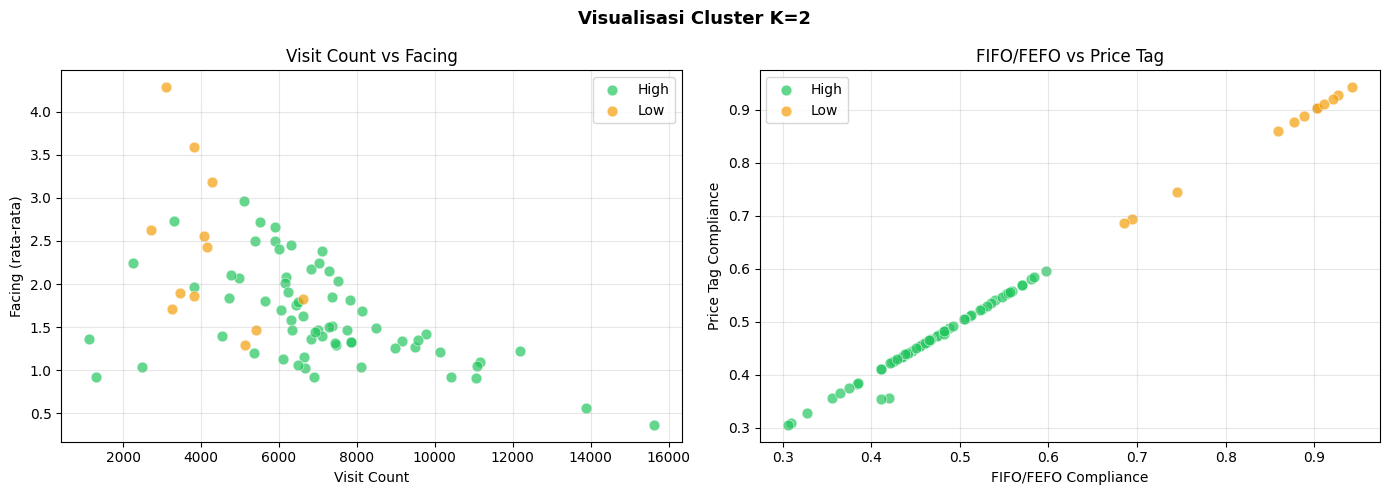

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Visualisasi Cluster K={BEST_K}', fontsize=13, fontweight='bold')

for idx, (cid, lbl) in enumerate(ordered_labels):
    mask  = df_grouped['cluster_label'] == lbl
    color = palette[idx % len(palette)]
    axes[0].scatter(df_grouped.loc[mask, 'visit_count'],
                    df_grouped.loc[mask, 'Facing'],
                    c=color, label=lbl, alpha=0.7, s=60,
                    edgecolors='white', linewidth=0.5)
    axes[1].scatter(df_grouped.loc[mask, 'Is FIFO/FEFO'],
                    df_grouped.loc[mask, 'Is Price Tag Available'],
                    c=color, label=lbl, alpha=0.7, s=60,
                    edgecolors='white', linewidth=0.5)

axes[0].set_xlabel('Visit Count'); axes[0].set_ylabel('Facing (rata-rata)')
axes[0].set_title('Visit Count vs Facing'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].set_xlabel('FIFO/FEFO Compliance'); axes[1].set_ylabel('Price Tag Compliance')
axes[1].set_title('FIFO/FEFO vs Price Tag'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_scatter_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Heatmap Korelasi Antar Fitur

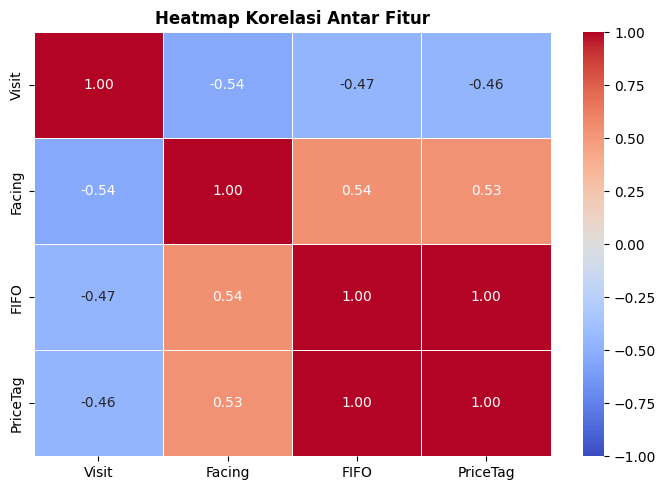

In [30]:
plt.figure(figsize=(7, 5))
corr = df_grouped[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1,
            xticklabels=['Visit', 'Facing', 'FIFO', 'PriceTag'],
            yticklabels=['Visit', 'Facing', 'FIFO', 'PriceTag'])
plt.title('Heatmap Korelasi Antar Fitur', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Export Hasil & Simpan Model

In [31]:
final_df = employee_info.merge(df_grouped, on='Username', how='right')
final_df['silhouette_sample'] = final_df['silhouette_sample'].round(4)

output_path = f'hasil clustering k{BEST_K}.xlsx'
final_df.to_excel(output_path, index=False)
print(f'Hasil disimpan ke: {output_path}')
print(f'   Total baris : {len(final_df)}')
print(f'   Kolom       : {final_df.columns.tolist()}')

os.makedirs('models', exist_ok=True)
joblib.dump(kmeans_final, 'models/kmeans_model.pkl')
joblib.dump(scaler,       'models/minmax_scaler.pkl')
print(' Model disimpan ke models/kmeans_model.pkl')
print(' Scaler disimpan ke models/minmax_scaler.pkl')

meta = {
    'k'                : BEST_K,
    'k_selection'      : {
        'silhouette'       : best_sil_k,
        'davies_bouldin'   : best_dbi_k,
        'calinski_harabasz': best_ch_k,
        'winner'           : BEST_K
    },
    'cluster_labels'   : {str(k): v for k, v in rank_labels.items()},
    'silhouette_score' : round(sil, 4),
    'davies_bouldin'   : round(dbi, 4),
    'calinski_harabasz': round(ch, 2),
    'inertia'          : round(sse, 2),
}
with open('cluster_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print(' Metadata evaluasi disimpan ke cluster_meta.json')
print(json.dumps(meta, indent=2))

Hasil disimpan ke: hasil clustering k2.xlsx
   Total baris : 79
   Kolom       : ['Username', 'Nama Karyawan', 'Area', 'Region', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available', 'visit_count', 'cluster', 'cluster_label', 'silhouette_sample']
 Model disimpan ke models/kmeans_model.pkl
 Scaler disimpan ke models/minmax_scaler.pkl
 Metadata evaluasi disimpan ke cluster_meta.json
{
  "k": 2,
  "k_selection": {
    "silhouette": 2,
    "davies_bouldin": 2,
    "calinski_harabasz": 2,
    "winner": 2
  },
  "cluster_labels": {
    "0": "High",
    "1": "Low"
  },
  "silhouette_score": 0.6182,
  "davies_bouldin": 0.5584,
  "calinski_harabasz": 109.85,
  "inertia": 5.91
}


## 11. Ringkasan Akhir

In [32]:
print('=' * 60)
print(f'      RINGKASAN HASIL CLUSTERING K={BEST_K}            ')
print('=' * 60)
print(f'  Total karyawan dianalisis : {len(final_df)}')
for lbl in label_order:
    n_k = (final_df['cluster_label'] == lbl).sum()
    print(f'  Cluster {lbl:<8}: {n_k} karyawan')
print()
print('  --- Evaluasi Model ---')
print(f'  Silhouette Score      : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index  : {dbi:.4f}  → {dbi_interp}')
print(f'  Calinski-Harabasz     : {ch:.2f}')
print(f'  Inertia (SSE)         : {sse:.2f}')
print()
print('  --- Karakteristik Cluster ---')
for lbl in label_order:
    sub = df_grouped[df_grouped['cluster_label'] == lbl]
    print(f'  [{lbl}] visit={sub["visit_count"].mean():.1f} | '
          f'facing={sub["Facing"].mean()*100:.1f}% | '
          f'fifo={sub["Is FIFO/FEFO"].mean()*100:.1f}% | '
          f'price={sub["Is Price Tag Available"].mean()*100:.1f}%')
print('=' * 60)

      RINGKASAN HASIL CLUSTERING K=2            
  Total karyawan dianalisis : 79
  Cluster High    : 67 karyawan
  Cluster Low     : 12 karyawan

  --- Evaluasi Model ---
  Silhouette Score      : 0.6182  → Cukup baik
  Davies-Bouldin Index  : 0.5584  → Baik
  Calinski-Harabasz     : 109.85
  Inertia (SSE)         : 5.91

  --- Karakteristik Cluster ---
  [High] visit=7062.1 | facing=161.9% | fifo=46.6% | price=46.4%
  [Low] visit=4158.5 | facing=239.5% | fifo=85.5% | price=85.5%
